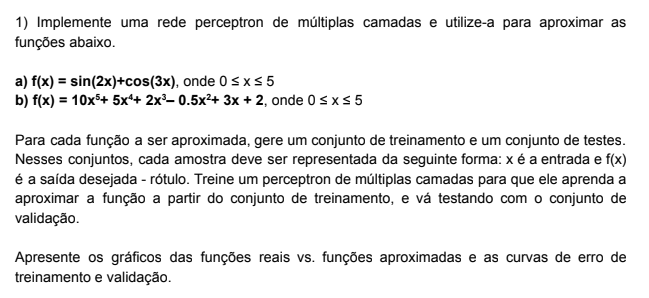

In [8]:
import numpy as np
import matplotlib as plt
import pandas as pd
import sklearn
from sklearn import model_selection
from sklearn.neural_network import MLPRegressor # Multi-layer Perceptron Regressor \ Rede Perceptron de Múltiplas Camadas

from sklearn.datasets import make_regression

In [9]:
def af(x): return np.sin(2*x) + np.cos(3*x)
afx_table = [(x, af(x)) for x in np.arange(0, 5.01, 0.01)]
afx_df = pd.DataFrame(afx_table, columns=['x', 'y'])

def bf(x): return 10*x**5 + 5*x**4 + 2*x**3 + - 0.5*x**2 + 3*x + 2
bfx_table = [(x, bf(x)) for x in np.arange(0, 5.01, 0.01)]
bfx_df = pd.DataFrame(bfx_table, columns=['x', 'y'])

In [10]:
bfx_df

,x,y
0,0.00,2.000000
1,0.01,2.029952
2,0.02,2.059817
3,0.03,2.089608
4,0.04,2.119342
...,...,...
496,4.96,33294.661324
497,4.97,33624.441502
498,4.98,33956.831025
499,4.99,34291.845351


In [11]:
afx_df_sample = afx_df.sample(n=400, random_state=42)
bfx_df_sample = bfx_df.sample(n=400, random_state=42)

In [12]:
bfx_df_sample

,x,y
362,3.62,7176.265990
73,0.73,8.194568
375,3.75,8516.228516
155,1.55,131.222628
104,1.04,24.844750
...,...,...
279,2.79,2043.397029
499,4.99,34291.845351
431,4.31,16763.706659
337,3.37,5074.471230


In [13]:
afx_trainX, afx_testX, afx_trainY, afx_testY = model_selection.train_test_split(
    afx_df_sample['x'].values.reshape(-1, 1), afx_df_sample['y'].values.reshape(-1, 1), test_size=0.2, random_state=42)

bfx_trainX, bfx_testX, bfx_trainY, bfx_testY = model_selection.train_test_split(
    bfx_df_sample['x'].values.reshape(-1, 1), bfx_df_sample['y'].values.reshape(-1, 1), test_size=0.2, random_state=42)

bfx_trainX

array([[1.55],
       [3.16],
       [2.45],
       [4.7 ],
       [2.98],
       [4.84],
       [3.14],
       [2.33],
       [3.31],
       [3.82],
       [0.06],
       [1.42],
       [1.17],
       [3.83],
       [3.8 ],
       [1.27],
       [2.3 ],
       [1.35],
       [1.77],
       [3.04],
       [0.38],
       [1.37],
       [4.96],
       [4.52],
       [0.16],
       [1.24],
       [4.09],
       [0.24],
       [1.  ],
       [2.82],
       [1.13],
       [3.  ],
       [3.67],
       [0.64],
       [4.33],
       [4.95],
       [4.9 ],
       [4.21],
       [1.97],
       [2.23],
       [2.18],
       [1.32],
       [0.3 ],
       [3.88],
       [0.76],
       [1.75],
       [4.76],
       [0.35],
       [0.07],
       [1.03],
       [2.24],
       [2.66],
       [1.47],
       [1.81],
       [0.42],
       [1.09],
       [0.59],
       [2.39],
       [3.53],
       [2.32],
       [4.1 ],
       [2.65],
       [2.94],
       [3.57],
       [1.45],
       [1.29],
       [0.

In [14]:
amodel = MLPRegressor(hidden_layer_sizes=(30, 50, 50, 50, 5, 5), 
                    max_iter=2000, 
                    tol=0.001, 
                    learning_rate_init=0.01, 
                    solver='sgd', 
                    activation='logistic', 
                    learning_rate='adaptive', 
                    verbose=True
                        )
amodel.fit(afx_trainX, afx_trainY)

c:\Users\rodri\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1593: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Iteration 1, loss = 0.77114649
Iteration 2, loss = 0.68582538
Iteration 3, loss = 0.58208686
Iteration 4, loss = 0.49350968
Iteration 5, loss = 0.42728779
Iteration 6, loss = 0.39406502
Iteration 7, loss = 0.38220290
Iteration 8, loss = 0.38651240
Iteration 9, loss = 0.39661500
Iteration 10, loss = 0.40444410
Iteration 11, loss = 0.40779908
Iteration 12, loss = 0.40572751
Iteration 13, loss = 0.40044334
Iteration 14, loss = 0.39480982
Iteration 15, loss = 0.38932304
Iteration 16, loss = 0.38610652
Iteration 17, loss = 0.38422752
Iteration 18, loss = 0.38289327
Training loss did not improve more than tol=0.001000 for 10 consecutive epochs. Setting learning rate to 0.002000
Iteration 19, loss = 0.38319662
Iteration 20, loss = 0.38369193
Iteration 21, loss = 0.38400437
Iteration 22, loss = 0.38475841
Iteration 23, loss = 0.38511207
Iteration 24, loss = 0.38544198
Iteration 25, loss = 0.38554771
Iteration 26, loss = 0.38564356
Iteration 27, loss = 0.38556990
Iteration 28, loss = 0.38547310

MLPRegressor(activation='logistic', hidden_layer_sizes=(30, 50, 50, 50, 5, 5),
             learning_rate='adaptive', learning_rate_init=0.01, max_iter=2000,
             solver='sgd', tol=0.001, verbose=True)

In [15]:
amodel.predict(afx_testX)

amodel.score(afx_testX, afx_testY)

-0.006352044448102001

In [16]:
bmodel = MLPRegressor(hidden_layer_sizes=(30, 50, 50, 50, 5, 5), 
                    max_iter=2000, 
                    tol=0.001, 
                    learning_rate_init=0.01, 
                    solver='sgd', 
                    activation='logistic', 
                    learning_rate='adaptive', 
                    verbose=True
                        )
bmodel.fit(bfx_trainX, bfx_trainY)

Iteration 1, loss = 48556668.98606598
Iteration 2, loss = 42716789.17634252
Iteration 3, loss = 37289761.68034641
Iteration 4, loss = 34941701.13743913
Iteration 5, loss = 35521258.08284935
Iteration 6, loss = 36109571.08731102


c:\Users\rodri\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:1593: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Iteration 7, loss = 36488939.47816408
Iteration 8, loss = 35995657.21948111
Iteration 9, loss = 35254749.44647245
Iteration 10, loss = 34945258.97858389
Iteration 11, loss = 34775627.95027722
Iteration 12, loss = 34889531.93925919
Iteration 13, loss = 35015388.11061548
Iteration 14, loss = 35012607.42797069
Iteration 15, loss = 34925342.08835795
Iteration 16, loss = 34820243.89097442
Iteration 17, loss = 34838666.02573279
Iteration 18, loss = 34839110.16403942
Iteration 19, loss = 34803067.43313321
Iteration 20, loss = 34800657.66895320
Iteration 21, loss = 34807313.44773842
Iteration 22, loss = 34805758.83671789
Training loss did not improve more than tol=0.001000 for 10 consecutive epochs. Setting learning rate to 0.002000
Iteration 23, loss = 34789000.38938758
Iteration 24, loss = 34792746.90957930
Iteration 25, loss = 34786743.49104057
Iteration 26, loss = 34787724.38638917
Iteration 27, loss = 34787950.69334258
Iteration 28, loss = 34789131.18708569
Iteration 29, loss = 34790130.3

MLPRegressor(activation='logistic', hidden_layer_sizes=(30, 50, 50, 50, 5, 5),
             learning_rate='adaptive', learning_rate_init=0.01, max_iter=2000,
             solver='sgd', tol=0.001, verbose=True)

In [17]:
bmodel.predict(bfx_testX)

bmodel.score(bfx_testX, bfx_testY)

-0.04941039059897845

c:\Users\rodri\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:402: UserWarning: X has feature names, but MLPRegressor was fitted without feature names
  warnings.warn(


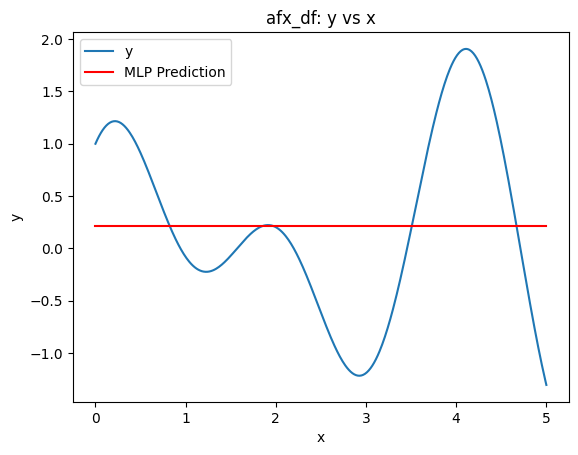

In [19]:
afx_df.plot(x='x', y='y', title='afx_df: y vs x', legend=False)

# Predict using the model for all x in afx_df
predicted_y = amodel.predict(afx_df[['x']])
plt.pyplot.plot(afx_df['x'], predicted_y, color='red', label='MLP Prediction')
plt.pyplot.legend()
plt.pyplot.xlabel('x')
plt.pyplot.ylabel('y')
plt.pyplot.show()

c:\Users\rodri\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:402: UserWarning: X has feature names, but MLPRegressor was fitted without feature names
  warnings.warn(


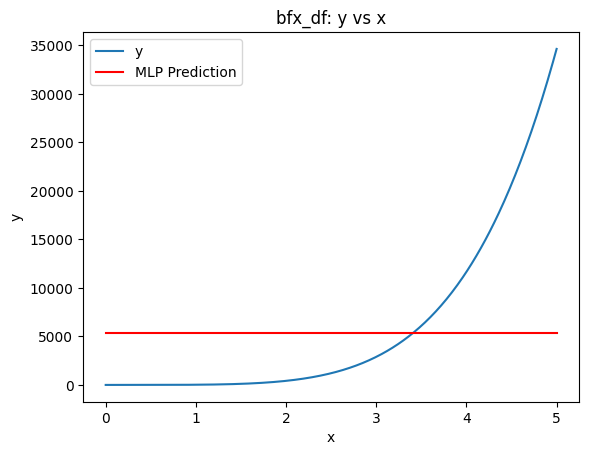

In [20]:
bfx_df.plot(x='x', y='y', title='bfx_df: y vs x', legend=False)

# Predict using the model for all x in bfx_df
predicted_y = bmodel.predict(bfx_df[['x']])
plt.pyplot.plot(bfx_df['x'], predicted_y, color='red', label='MLP Prediction')
plt.pyplot.legend()
plt.pyplot.xlabel('x')
plt.pyplot.ylabel('y')
plt.pyplot.show()